🛰️ Green Area Analyzer using Google Earth Engine & Machine Learning
==================================================================

📌 Project Overview:
This notebook is designed to monitor and forecast vegetation trends by analyzing NDVI (Normalized Difference Vegetation Index) over time using satellite imagery from the Sentinel-2 dataset, accessed via the Google Earth Engine API.

The tool processes satellite images for a user-defined region and time period, extracts NDVI values, and uses various regression models to predict the greenness of that area in future years. It supports trend visualization and comparative analysis using multiple ML models.

🌿 Use Case:
This project is useful for environmental monitoring, deforestation tracking, agricultural assessment, and climate change studies. It provides a simple pipeline to understand how green cover is changing and how it might evolve in the coming years.

--------------------------------------------------------
🧠 Machine Learning Models Used:
--------------------------------------------------------
1. Random Forest Regressor (Robust and interpretable)
2. Support Vector Regressor (Works well with nonlinear data)
3. Gradient Boosting Regressor (Accurate, slow but powerful)
4. Decision Tree Regressor (Simple and fast)
5. XGBoost Regressor (Optimized and scalable boosting)

--------------------------------------------------------
📦 Python Libraries Required:
--------------------------------------------------------
- earthengine-api: Interface to Google Earth Engine
- numpy: Array manipulation
- pandas: Dataframe operations
- matplotlib: Data visualization
- scikit-learn: Machine learning algorithms
- xgboost: Gradient boosting model
- mpl_toolkits.axes_grid1: Advanced plotting (included with matplotlib)

--------------------------------------------------------
🛠️ Workflow:
--------------------------------------------------------
1. Authenticate and initialize the Earth Engine API.
2. Select location coordinates (latitude-longitude bounding box).
3. Fetch Sentinel-2 imagery filtered by date and cloud coverage.
4. Compute NDVI from bands B8 (NIR) and B4 (Red).
5. Store NDVI data with timestamps.
6. Train multiple regression models on historical NDVI data.
7. Predict NDVI values for future time frames.
8. Plot original data, fitted model, and forecasted trend.
9. Automatically classify the vegetation trend (increasing/decreasing).

--------------------------------------------------------
📅 Parameters:
--------------------------------------------------------
- `locations`: Dictionary with region names and bounding box coordinates.
- `train_years`: Number of years to train the model on historical data.
- `predict_years`: Number of years to forecast into the future.

--------------------------------------------------------
📍 Example Use:
--------------------------------------------------------
- Analyzing forest greenness over the Amazon basin from 2019–2025.
- Predicting NDVI trends to monitor possible deforestation or seasonal variation.
- Comparing the performance of different ML models for environmental forecasting.

--------------------------------------------------------
👨‍💻 Author: Chinmay Bansal
📅 Year: 2025

In [ ]:
%pip install earthengine-api numpy pandas matplotlib scikit-learn xgboost
%pip install --upgrade xgboost

^C
Note: you may need to restart the kernel to use updated packages.


In [1]:
import ee
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler

c:\Data\projects\Python\SatteliteGreenryPrediction\venv\lib\site-packages\google\api_core\_python_version_support.py:234: FutureWarning: You are using a non-supported Python version (3.10.11). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)


In [2]:
try:
    ee.Initialize()
except Exception as e:
    ee.Authenticate()
    ee.Initialize(project='satellite-454512')


Successfully saved authorization token.


In [3]:
class GreenAreaAnalyzer:
    def __init__(self, locations, train_years=5, predict_years=2):
        self.locations = locations
        self.train_years = train_years
        self.predict_years = predict_years

    def fetch_and_calculate_ndvi(self, name, coords, start_date, end_date):
        area_of_interest = ee.Geometry.Rectangle([coords[1], coords[0], coords[3], coords[2]])
        collection = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                      .filterBounds(area_of_interest)
                      .filterDate(start_date, end_date)
                      .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))
                      .select(['B8', 'B4']))
        images = collection.toList(collection.size()).getInfo()

        if len(images) == 0:
            print(f"No images found for {name} in the given date range.")
            return name, pd.DataFrame()

        ndvi_values, dates = [], []
        for image_info in images:
            image = ee.Image(image_info['id'])
            timestamp = image_info['properties']['system:time_start'] / 1000
            date = datetime.fromtimestamp(timestamp)
            ndvi = image.normalizedDifference(['B8', 'B4']).rename('NDVI')
            result = ndvi.reduceRegion(
                reducer=ee.Reducer.mean(),
                geometry=area_of_interest,
                scale=30,
                maxPixels=1e13
            ).getInfo()
            ndvi_value = result.get('NDVI')
            if ndvi_value is not None:
                ndvi_values.append(float(ndvi_value))
                dates.append(date)

        return name, pd.DataFrame({'Date': dates, 'NDVI': ndvi_values})

    def analyze_sequential(self, start_date, end_date):
        results = {}
        for loc in self.locations.items():
            name, data = self.fetch_and_calculate_ndvi(loc[0], loc[1], start_date, end_date)
            results[name] = data
        return results

    def plot_and_predict(self):
        base_year = 2019
        train_start_date = datetime(base_year, 1, 1).strftime('%Y-%m-%d')
        train_end_date = datetime(base_year + self.train_years, 1, 1).strftime('%Y-%m-%d')
        predict_end_date = datetime(base_year + self.train_years + self.predict_years, 1, 1).strftime('%Y-%m-%d')

        results = self.analyze_sequential(train_start_date, train_end_date)
        actual_future_results = self.analyze_sequential(train_end_date, predict_end_date)

        regressors = {
            'RandomForest': RandomForestRegressor(n_estimators=100, random_state=42),
            'SVR': SVR(),
            'GradientBoosting': GradientBoostingRegressor(n_estimators=100, random_state=42),
            'DecisionTree': DecisionTreeRegressor(random_state=42),
            'XGBoost': XGBRegressor(n_estimators=100, random_state=42)
        }

        for name, df in results.items():
            if df.empty:
                print(f"No data available for {name}.")
                continue

            df['Timestamp'] = pd.to_datetime(df['Date']).astype('int64') / 10**9
            X = df['Timestamp'].values.reshape(-1, 1)
            y = df['NDVI'].values.reshape(-1, 1)

            scaler_X = StandardScaler()
            scaler_y = StandardScaler()
            X_scaled = scaler_X.fit_transform(X)
            y_scaled = scaler_y.fit_transform(y)

            future_dates = pd.date_range(start=train_end_date, end=predict_end_date, freq='ME')
            future_timestamps = (future_dates - pd.Timestamp("1970-01-01")) // pd.Timedelta('1s')
            future_timestamps = np.array(future_timestamps).reshape(-1, 1)
            future_timestamps_scaled = scaler_X.transform(future_timestamps)

            n_rows = len(regressors)
            fig, axs = plt.subplots(n_rows, 2, figsize=(20, 6 * n_rows), squeeze=False)

            train_trend = 'increasing' if y[-1][0] > y[0][0] else 'decreasing'
            print(f"🌿 Greenery Trend for {name} based on Training Data: {train_trend}")

            for i, (reg_name, regressor) in enumerate(regressors.items()):
                regressor.fit(X_scaled, y_scaled.ravel())

                ax = axs[i, 0]
                ax.scatter(df['Date'], y.flatten(), color='blue', label='Actual NDVI', s=30)

                fitted = scaler_y.inverse_transform(
                    regressor.predict(X_scaled).reshape(-1, 1)
                ).flatten()
                ax.plot(df['Date'], fitted, color='orange', label='Fitted NDVI', linewidth=1.5)

                predictions_scaled = regressor.predict(future_timestamps_scaled)
                predictions = scaler_y.inverse_transform(predictions_scaled.reshape(-1, 1)).flatten()

                ax.plot(future_dates, predictions, color='green', label='Predicted NDVI', linewidth=1.5)
                ax.set_title(f'{reg_name} - {name}')
                ax.legend()
                ax.grid(True)

                trend = 'increasing' if predictions[-1] > predictions[0] else 'decreasing'

                ax2 = axs[i, 1]
                ax2.plot(future_dates, predictions,
                         color='green' if trend == 'increasing' else 'red', marker='o')
                ax2.set_title(f'Greenery Trend - {reg_name} ({trend})')
                ax2.grid(True)
                ax2.set_yticks(np.arange(min(predictions) - 0.005, max(predictions) + 0.005, 0.005))

            plt.tight_layout()
            plt.show()

In [5]:
if __name__ == "__main__":
  locations = {
    'Amazon Rainforest (Brazil)': [-3.5, -60.0, -3.0, -59.5],
  }

  analyzer = GreenAreaAnalyzer(locations)
  analyzer.plot_and_predict()

KeyboardInterrupt: 

## Conclusion and evaluation note

The original plots compare fitted curves and future projections, but visual inspection alone does not establish which model forecasts best. Use the **Chronological Holdout Evaluation** section below to compare Prophet and the regression models against later, observed satellite NDVI values using MAE, RMSE, and R². The best model should be selected from the holdout results, not assumed in advance.


# Chronological Holdout Evaluation: Prophet vs. Regression Models

This section evaluates predictions on held-out observations fetched from Sentinel-2. It mirrors the Streamlit app's preprocessing: `COPERNICUS/S2_SR_HARMONIZED`, cloud percentage below 10%, NDVI = normalized difference of B8 and B4, regional mean via `reduceRegion`, scale 250 m, chronological sorting, and a trailing rolling mean with window 3 and `min_periods=1`.

**Evaluation setup**
- Training period: 2019-01-01 through 2023-12-31 (end-exclusive boundary 2024-01-01)
- Test period: 2024-01-01 through 2025-12-31 (end-exclusive boundary 2026-01-01)
- Target: three-observation smoothed NDVI, matching the app
- Models: Prophet, Random Forest, SVR, Gradient Boosting, Decision Tree, XGBoost
- Metrics: MAE, RMSE, R²; Prophet prediction-interval coverage
- Latency: Earth Engine fetch time, model fitting time, prediction time, and prediction latency per sample

The code reports measured values when executed with Earth Engine access. Results are not hard-coded.

In [ ]:
%pip install prophet

## Run the holdout evaluation

The code below trains Prophet, Random Forest, SVR, Gradient Boosting, Decision Tree, and XGBoost on the training period, predicts NDVI for the observed test-month dates, and prints the model parameters and holdout metrics. The feature scaler is fitted on training timestamps only. No test observations are used to fit the models.

c:\Data\projects\Python\SatteliteGreenryPrediction\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


\n========================================================================================
LOCATION: Amazon Rainforest (Brazil)
Training observations: 85
Test observations: 41
Train dates: 2019-03-19 19:53:33.848000 through 2023-11-28 19:53:29.371000
Test dates: 2024-01-30 20:03:26.690000 through 2025-08-24 20:03:45.707000
Data fetch latency: 2.755 s (train 1.540 s, test 1.214 s)


10:18:36 - cmdstanpy - INFO - Chain [1] start processing
10:18:37 - cmdstanpy - INFO - Chain [1] done processing


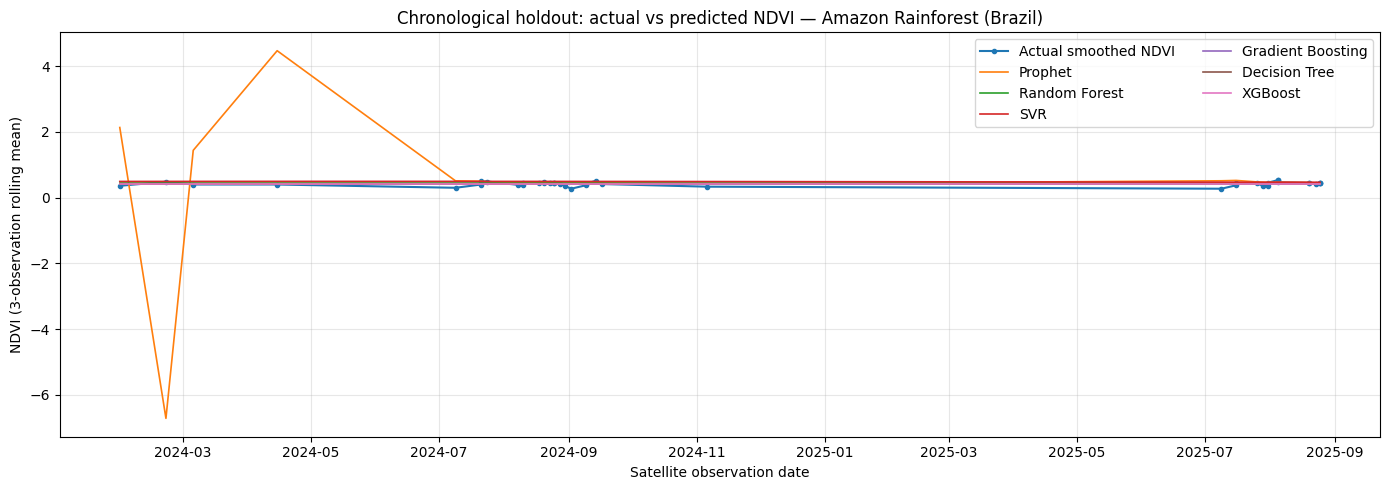

\nHOLDOUT EVALUATION (lower MAE/RMSE is better; R² may be negative)


,Location,Model,Train observations,Test observations,MAE,RMSE,R2,Prophet interval coverage
5,Amazon Rainforest (Brazil),XGBoost,85,41,0.04694,0.06119,-0.00924,NaN
4,Amazon Rainforest (Brazil),Decision Tree,85,41,0.04690,0.06122,-0.01032,NaN
3,Amazon Rainforest (Brazil),Gradient Boosting,85,41,0.04667,0.06150,-0.01934,NaN
1,Amazon Rainforest (Brazil),Random Forest,85,41,0.04641,0.06209,-0.03924,NaN
2,Amazon Rainforest (Brazil),SVR,85,41,0.07113,0.08980,-1.17388,NaN
0,Amazon Rainforest (Brazil),Prophet,85,41,0.39497,1.33375,-478.50061,0.56098


\nLATENCY (measured on this notebook run; excludes Earth Engine data fetching from fit+predict)


,Location,Model,Fetch latency (s),Fit latency (s),Predict latency (s),Fit+predict latency (s),Prediction latency (ms/sample)
4,Amazon Rainforest (Brazil),Decision Tree,2.75454,0.00143,0.00022,0.00165,0.00531
2,Amazon Rainforest (Brazil),SVR,2.75454,0.00614,0.00218,0.00832,0.05317
3,Amazon Rainforest (Brazil),Gradient Boosting,2.75454,0.10061,0.00135,0.10196,0.03281
1,Amazon Rainforest (Brazil),Random Forest,2.75454,0.25490,0.01120,0.26610,0.27324
0,Amazon Rainforest (Brazil),Prophet,2.75454,1.33301,0.40962,1.74263,9.99074
5,Amazon Rainforest (Brazil),XGBoost,2.75454,2.23906,0.00490,2.24396,0.11947


\nMODEL PARAMETERS


,Location,Model,Parameters
0,Amazon Rainforest (Brazil),Prophet,"{""changepoint_prior_scale"": 0.05, ""daily_seaso..."
1,Amazon Rainforest (Brazil),Random Forest,"{""bootstrap"": true, ""ccp_alpha"": 0.0, ""criteri..."
2,Amazon Rainforest (Brazil),SVR,"{""memory"": null, ""standardscaler"": ""StandardSc..."
3,Amazon Rainforest (Brazil),Gradient Boosting,"{""alpha"": 0.9, ""ccp_alpha"": 0.0, ""criterion"": ..."
4,Amazon Rainforest (Brazil),Decision Tree,"{""ccp_alpha"": 0.0, ""criterion"": ""squared_error..."
5,Amazon Rainforest (Brazil),XGBoost,"{""base_score"": null, ""booster"": null, ""callbac..."


\nBest model per location by lowest holdout RMSE:


,Location,Model,Train observations,Test observations,MAE,RMSE,R2,Prophet interval coverage
5,Amazon Rainforest (Brazil),XGBoost,85,41,0.04694,0.06119,-0.00924,NaN


Saved metrics, latency, parameter, and per-location prediction CSV files.


In [6]:
import time
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ee

from prophet import Prophet
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

warnings.filterwarnings("default")

# Match the Streamlit app's defaults and preprocessing.
EVAL_START = "2019-01-01"
TRAIN_END = "2024-01-01"  # end-exclusive: five calendar years of training data
TEST_END = "2026-01-01"   # end-exclusive: two calendar years of held-out data
APP_SCALE_METERS = 250
SMOOTH_WINDOW = 3
CLOUD_PERCENT_LIMIT = 10
FLEXIBILITY = 0.05

# Same image collection, cloud filter, NDVI equation, spatial mean, and scale as app.py.
def fetch_app_style_ndvi(coords, start_date, end_date, scale=APP_SCALE_METERS):
    aoi = ee.Geometry.Rectangle([coords[1], coords[0], coords[3], coords[2]])
    collection = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(aoi)
        .filterDate(start_date, end_date)
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", CLOUD_PERCENT_LIMIT))
    )

    def calculate_ndvi(image):
        ndvi = image.normalizedDifference(["B8", "B4"]).rename("NDVI")
        mean_dict = ndvi.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=aoi,
            scale=scale,
            maxPixels=1e13
        )
        return ee.Feature(None, {
            "NDVI": mean_dict.get("NDVI"),
            "system:time_start": image.get("system:time_start")
        })

    t0 = time.perf_counter()
    feature_collection = collection.map(calculate_ndvi)
    info = feature_collection.getInfo()
    fetch_seconds = time.perf_counter() - t0

    dates, values = [], []
    for feature in info.get("features", []):
        props = feature.get("properties", {})
        value = props.get("NDVI")
        timestamp = props.get("system:time_start")
        if value is not None and timestamp is not None:
            dates.append(datetime.fromtimestamp(timestamp / 1000.0))
            values.append(float(value))

    frame = pd.DataFrame({"Date": dates, "NDVI": values})
    if frame.empty:
        return frame, fetch_seconds
    frame = frame.dropna().sort_values("Date").reset_index(drop=True)
    return frame, fetch_seconds

# Timestamp is the only predictor, matching the notebook's regression models.
model_specs = {
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "SVR": make_pipeline(StandardScaler(), SVR(kernel="rbf", C=1.0, epsilon=0.1, gamma="scale")),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "XGBoost": XGBRegressor(
        n_estimators=100, random_state=42,
        objective="reg:squarederror", eval_metric="rmse"
    )
}

metrics_rows = []
latency_rows = []
parameter_rows = []
prediction_tables = {}

for location_name, coords in locations.items():
    print("\\n" + "=" * 88)
    print("LOCATION:", location_name)

    train_raw, train_fetch_s = fetch_app_style_ndvi(coords, EVAL_START, TRAIN_END)
    test_raw, test_fetch_s = fetch_app_style_ndvi(coords, TRAIN_END, TEST_END)
    total_fetch_s = train_fetch_s + test_fetch_s

    if train_raw.empty or test_raw.empty:
        print(f"Skipping: empty data (train rows={len(train_raw)}, test rows={len(test_raw)}).")
        latency_rows.append({
            "Location": location_name, "Model": "Data fetch",
            "Fetch latency (s)": total_fetch_s, "Fit latency (s)": np.nan,
            "Predict latency (s)": np.nan, "Fit+predict latency (s)": np.nan,
            "Prediction latency (ms/sample)": np.nan
        })
        continue

    # Same as app.py: chronological sort and trailing rolling mean, window=3,
    # min_periods=1. Smooth the combined timeline before splitting so the first
    # test values use the preceding observed values, as a trailing rolling window should.
    combined = pd.concat([train_raw, test_raw], ignore_index=True)
    combined = combined.dropna(subset=["Date", "NDVI"]).sort_values("Date").reset_index(drop=True)
    combined["NDVI_Smooth"] = combined["NDVI"].rolling(
        window=SMOOTH_WINDOW, min_periods=1
    ).mean()

    train_df = combined[
        (combined["Date"] >= pd.Timestamp(EVAL_START)) &
        (combined["Date"] < pd.Timestamp(TRAIN_END))
    ].copy()
    test_df = combined[
        (combined["Date"] >= pd.Timestamp(TRAIN_END)) &
        (combined["Date"] < pd.Timestamp(TEST_END))
    ].copy()

    if len(train_df) < 12 or len(test_df) < 3:
        print(f"Skipping: insufficient observations (train={len(train_df)}, test={len(test_df)}).")
        continue

    train_prophet = train_df[["Date", "NDVI_Smooth"]].rename(
        columns={"Date": "ds", "NDVI_Smooth": "y"}
    ).sort_values("ds")
    test_prophet = test_df[["Date", "NDVI_Smooth"]].rename(
        columns={"Date": "ds", "NDVI_Smooth": "y"}
    ).sort_values("ds")
    y_test = test_prophet["y"].to_numpy()
    test_dates = test_prophet["ds"].to_numpy()

    print(f"Training observations: {len(train_df)}")
    print(f"Test observations: {len(test_df)}")
    print(f"Train dates: {train_df['Date'].min()} through {train_df['Date'].max()}")
    print(f"Test dates: {test_df['Date'].min()} through {test_df['Date'].max()}")
    print(f"Data fetch latency: {total_fetch_s:.3f} s (train {train_fetch_s:.3f} s, test {test_fetch_s:.3f} s)")

    predictions = pd.DataFrame({"Date": test_dates, "Actual_NDVI_Smooth": y_test})

    # Prophet parameters intentionally match app.py's model configuration.
    prophet_params = {
        "changepoint_prior_scale": FLEXIBILITY,
        "yearly_seasonality": True,
        "weekly_seasonality": False,
        "daily_seasonality": False
    }
    model = Prophet(**prophet_params)
    fit_start = time.perf_counter()
    model.fit(train_prophet)
    fit_s = time.perf_counter() - fit_start
    pred_start = time.perf_counter()
    forecast = model.predict(test_prophet[["ds"]])
    pred_s = time.perf_counter() - pred_start
    pred = forecast["yhat"].to_numpy()
    predictions["Prophet"] = pred

    def add_metrics(model_name, actual, predicted, fit_latency, predict_latency,
                    lower=None, upper=None, params=None):
        coverage = np.nan
        if lower is not None and upper is not None:
            coverage = float(np.mean((actual >= lower) & (actual <= upper)))
        metrics_rows.append({
            "Location": location_name,
            "Model": model_name,
            "Train observations": len(train_df),
            "Test observations": len(test_df),
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": float(np.sqrt(mean_squared_error(actual, predicted))),
            "R2": r2_score(actual, predicted) if len(actual) >= 2 else np.nan,
            "Prophet interval coverage": coverage
        })
        latency_rows.append({
            "Location": location_name,
            "Model": model_name,
            "Fetch latency (s)": total_fetch_s,
            "Fit latency (s)": fit_latency,
            "Predict latency (s)": predict_latency,
            "Fit+predict latency (s)": fit_latency + predict_latency,
            "Prediction latency (ms/sample)": 1000 * predict_latency / max(1, len(actual))
        })
        parameter_rows.append({
            "Location": location_name,
            "Model": model_name,
            "Parameters": json.dumps(params or {}, default=str, sort_keys=True)
        })

    add_metrics(
        "Prophet", y_test, pred, fit_s, pred_s,
        lower=forecast["yhat_lower"].to_numpy(),
        upper=forecast["yhat_upper"].to_numpy(),
        params=prophet_params
    )

    # Standardize timestamps using training dates only. SVR's pipeline scales
    # its own input, while other regressors receive the training-fitted scaler.
    train_x = (pd.to_datetime(train_df["Date"]).astype("int64") // 10**9).to_numpy().reshape(-1, 1)
    test_x = (pd.to_datetime(test_df["Date"]).astype("int64") // 10**9).to_numpy().reshape(-1, 1)
    timestamp_scaler = StandardScaler()
    train_x_scaled = timestamp_scaler.fit_transform(train_x)
    test_x_scaled = timestamp_scaler.transform(test_x)

    for model_name, estimator in model_specs.items():
        fitted = clone(estimator)
        x_train = train_x if model_name == "SVR" else train_x_scaled
        x_test = test_x if model_name == "SVR" else test_x_scaled

        fit_start = time.perf_counter()
        fitted.fit(x_train, train_df["NDVI_Smooth"].to_numpy())
        fit_s = time.perf_counter() - fit_start
        pred_start = time.perf_counter()
        pred = fitted.predict(x_test)
        pred_s = time.perf_counter() - pred_start

        predictions[model_name] = pred
        add_metrics(
            model_name, y_test, pred, fit_s, pred_s,
            params=fitted.get_params(deep=True)
        )

    prediction_tables[location_name] = predictions
    plt.figure(figsize=(14, 5))
    plt.plot(predictions["Date"], predictions["Actual_NDVI_Smooth"],
             marker=".", linewidth=1.5, label="Actual smoothed NDVI")
    for model_name in ["Prophet", "Random Forest", "SVR",
                       "Gradient Boosting", "Decision Tree", "XGBoost"]:
        plt.plot(predictions["Date"], predictions[model_name],
                 linewidth=1.2, label=model_name)
    plt.title(f"Chronological holdout: actual vs predicted NDVI — {location_name}")
    plt.xlabel("Satellite observation date")
    plt.ylabel("NDVI (3-observation rolling mean)")
    plt.legend(ncol=2)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

metrics_df = pd.DataFrame(metrics_rows)
latency_df = pd.DataFrame(latency_rows)
parameters_df = pd.DataFrame(parameter_rows)

if metrics_df.empty:
    print("\\nNo model metrics were generated. Check Earth Engine authentication, date coverage, and region coordinates.")
else:
    print("\\nHOLDOUT EVALUATION (lower MAE/RMSE is better; R² may be negative)")
    display(metrics_df.sort_values(["Location", "RMSE"]).round(5))

    print("\\nLATENCY (measured on this notebook run; excludes Earth Engine data fetching from fit+predict)")
    display(latency_df.sort_values(["Location", "Fit+predict latency (s)"]).round(5))

    print("\\nMODEL PARAMETERS")
    display(parameters_df)

    print("\\nBest model per location by lowest holdout RMSE:")
    display(metrics_df.loc[metrics_df.groupby("Location")["RMSE"].idxmin()].round(5))

    metrics_df.to_csv("ndvi_holdout_model_metrics.csv", index=False)
    latency_df.to_csv("ndvi_holdout_model_latency.csv", index=False)
    parameters_df.to_csv("ndvi_holdout_model_parameters.csv", index=False)
    for location_name, table in prediction_tables.items():
        safe_name = "".join(ch if ch.isalnum() else "_" for ch in location_name)
        table.to_csv(f"ndvi_holdout_predictions_{safe_name}.csv", index=False)

    print("Saved metrics, latency, parameter, and per-location prediction CSV files.")


## How to interpret the results

- **MAE**: mean absolute NDVI error; lower is better.
- **RMSE**: penalizes larger errors; lower is better.
- **R²**: measures explanatory performance on the held-out months; it can be negative.
- **80% interval coverage**: for Prophet, the fraction of actual test values inside the model's nominal 80% prediction interval. It is not an accuracy score.

The model with the lowest test RMSE is the best performer for that location and split, but it should not automatically be described as universally best. For a stronger assessment, use rolling-origin time-series cross-validation and retain a final untouched test period.

**Important:** the notebook must be run with valid Google Earth Engine credentials to obtain the real test metrics. No new metric values are hard-coded here; the displayed numbers are calculated from the fetched satellite observations when these cells run.